In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import pandas as pd
from scipy.integrate import odeint, solve_ivp
import itertools
import matplotlib        as mpl
rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 20})

1.naloga

In [4]:
def binarna(y,x, alpha, beta):
    A,A_,B = y
    vA = -A*A + 2*alpha*A*A_
    vA_ = A*A - alpha*A*A_ - beta*A_
    vB = beta*A_
    return [vA, vA_, vB]
def binarna_stac(y,x, alpha, beta):
    A,A_,B = y
    A_ = A*A / (alpha*A+beta)
    vA = -A*A + 2*alpha*A*A_
    vA_ = A*A - alpha*A*A_ - beta*A_ #=0
    vB = beta*A_
    return [vA, vA_, vB]
def normiranje(data):
    '''normiranje na delež'''
    rez = []
    for podatki in range(len(data)):
        A = []
        for i in range(len(data[podatki])):
            vsota_i = 0
            for j in range(len(data)):
                vsota_i += data[j][i]
            a = data[podatki][i] / vsota_i
            A.append(a)
        rez.append(A)
    return rez

In [5]:
def ena(rq):
    alpha = 1000 #podatek
    A0 = 0.01 #A0 zaradi numerike !!!
    #rq = 0.1 #parameter = 10, 1 ali 0.1
    beta = alpha * rq
    x = np.linspace(0,100,1000)
    X = [i / x[-1] for i in x] #normiran čas
    print(rq)
    začetno = [A0, 0, 0] #A, A_, B=C

    r = odeint(binarna,začetno,x,args=(alpha,beta))
    A, A_, B = r.T
    An = np.array([i/max(A) for i in A])
    A_n = np.array([i/max(A_) for i in A_])
    Bn = np.array([i/max(B) for i in B])
    An, A_n, Bn = normiranje([A,A_,B])
    #np.clip(A, 0,1, out=An)
    #np.clip(A_, 0,1, out=A_n)
    #np.clip(B, 0,1, out=Bn)
    data_nenorm = pd.DataFrame({
        'A':A, 'A*':A_, 'B':B, 'C':B
    }, index=X)
    data = pd.DataFrame({
        '$A$':An, '$A^*$':A_n, '$B,C$':Bn#, 'C':Bn
    }, index=X)
    #ax = data.plot.area()
    #ax = data_nenorm.plot.area()
    #plt.title('nenormirano')
    plt.figure(figsize=(8,5))
    plt.plot(X,An,'b', label='$A$')
    plt.plot(X,A_n,'r',label='$A^*$')
    plt.plot(X,Bn,'g', label='$B, C$')
    #plt.legend(bbox_to_anchor=(1, 1), ncol=1)
    #plt.tight_layout()


    r_stac = odeint(binarna_stac,začetno,x,args=(alpha,beta))
    A, A_, B = r_stac.T
    An, A_n, Bn = normiranje([A,A_,B])
    data = pd.DataFrame({
        '$A$':An, '$A^*$':A_n, '$B,C$':Bn#, 'C':Bn
    }, index=X)
    #ax = data.plot.area()
    plt.plot(X,An,'b:', label='$A_{st}$',linewidth=5.0)
    plt.plot(X,A_n,'r:', label='$A^*_{st}$',linewidth=5.0)
    plt.plot(X,Bn,'g:', label='$B_{st}, C_{st}$',linewidth=5.0)
    plt.legend(bbox_to_anchor=(1, 1), ncol=1)
    plt.xlabel('čas')
    plt.ylabel('koncentracija')
    plt.tight_layout()
    #plt.savefig(f'slike/obratno_qp_zanimivo.pdf')
    plt.show()

    napaka_A.append(abs(r.T[0] - r_stac.T[0]) / np.average([r.T[0], r_stac.T[0]]))
    napaka_A_.append(abs(r.T[1] - r_stac.T[1]) / np.average([r.T[1], r_stac.T[1]]))
    napaka_B.append(abs(r.T[2] - r_stac.T[2]) / np.average([r.T[2], r_stac.T[2]]))

0.05


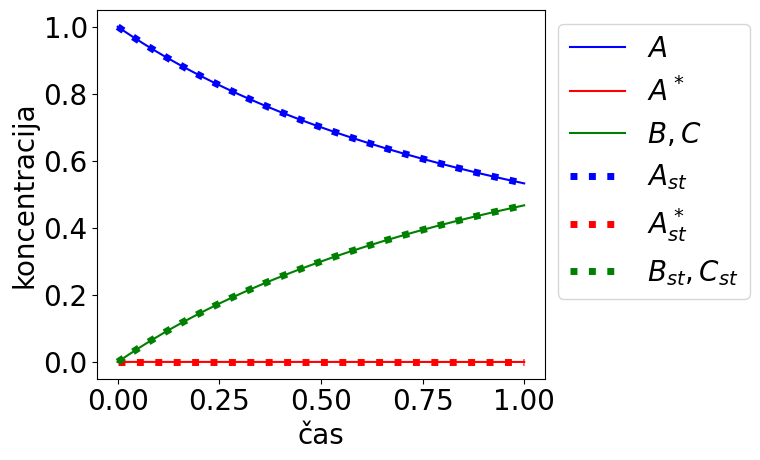

0.1


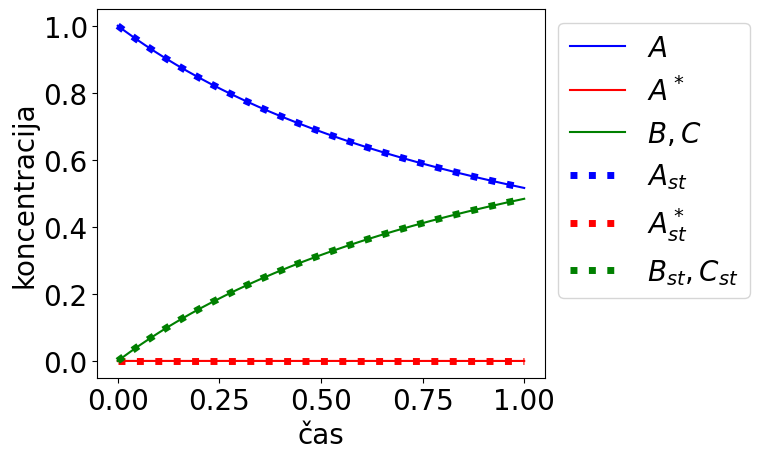

1


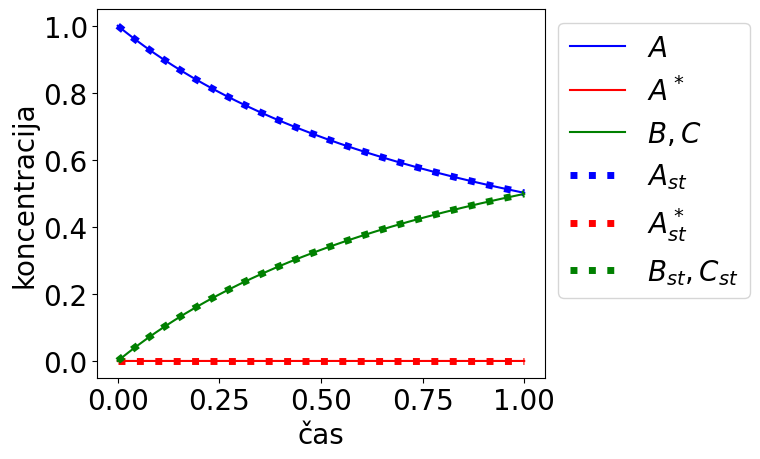

10


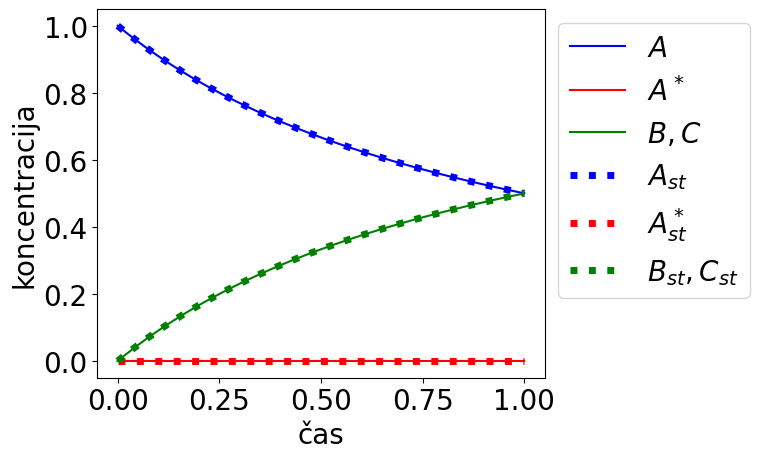

In [6]:
param = [0.05,0.1,1,10]
napaka_A = []
napaka_A_ = []
napaka_B = []
for i in param:
    ena(i)

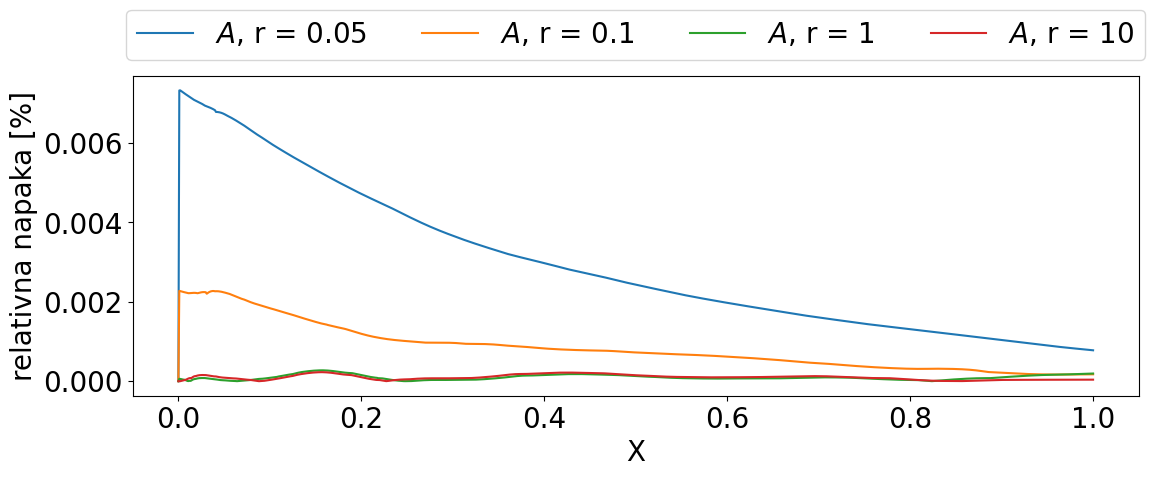

In [7]:
x = np.linspace(0,100,1000)
X = [i / x[-1] for i in x] #normiran čas
plt.figure(figsize=(12,5))
for i in range(len(napaka_A)):
    plt.plot(X, napaka_A[i]*100, label=f'$A$, r = {param[i]}')
    #plt.plot(X, napaka_A_, label='$A^*$')
    #plt.plot(X, napaka_B[i]*100, label=f'$B$, r = {param[i]}')
plt.legend(bbox_to_anchor=(0.5, 1.25), loc='upper center', ncol=5)
plt.tight_layout()
plt.xlabel('X')
plt.ylabel('relativna napaka [%]')
#plt.savefig('slike/napaka_od_r.pdf')
plt.show()

2.naloga

In [8]:
def brom_vse(y,x, p,q, r,s, t):
    H2, Br2, HBr, H, Br = y
    vH2=s*HBr*H - r*Br*H2
    vBr2=q*Br*Br - p*Br2 - t*H*Br2
    vHBr=r*Br*H2 -s*HBr*H + t*H*Br2
    vH=r*Br*H2 - s*HBr*H - t*H*HBr
    vBr=p*Br2 - q*Br*Br + s*HBr*H - r*Br*H2 + t*H*Br2
    return [vH2, vBr2, vHBr, vH, vBr] #H2, Br2, HBr, H, Br
    #return [s**HBr*H - r*Br*H2, q*Br*Br - p*Br2 - t*H*Br2, r*Br*H2 -s*HBr*H + t*H*Br2, 0, 0] #H2, Br2, HBr, H, Br
def brom_stac(y,x, p,q,r,s,t):
    H2, Br2, HBr, H, Br = y
    vHBr = 2*r*t/s * (2*p/q)**(0.5) * Br2**(0.5) * H2 / (t/s + HBr/Br2)
    vBr =0
    vH =0
    vBr2 = q*Br*Br - q*Br2 - t*H*Br2
    vH2 = s*H*HBr - r*Br*H2
    return [vH2, vBr2, vHBr, vH, vBr]
def zamenjava(x):
    '''zamenja negativne vrednosti v 0, za prikaz'''
    rez = []
    for seznam in x:
        for i in seznam:
            if i < 0:
                seznam[np.where(seznam == i)] = 0
        rez.append(seznam)
    return rez
def empirična(Br2, H2, HBr, k, m):
    return k*H2*Br2**(0.5) / (m+HBr/Br2)
def v_HBr(y, p,q,r,s,t):
    H2, Br2, HBr, H, Br = y
    vHBr = 2*r*t/s * (2*p/q)**(0.5) * Br2**(0.5) * H2 / (t/s + HBr/Br2)
    return vHBr

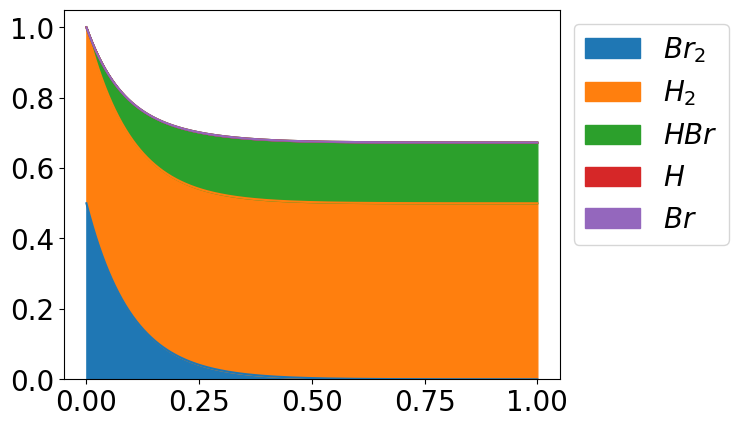

2.5 1


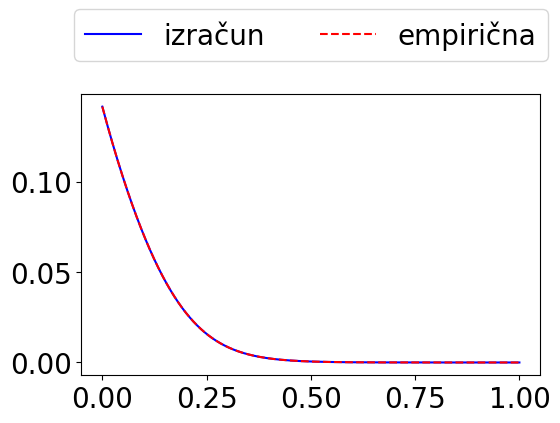

In [9]:
k = 1 #param
p = 1
q = 1
s = 1
m = 2.5 #podatek
r = k/2/m * (q/2/p)**(0.5)
t = m*s
x = np.linspace(0, 10, 1000)
X = [i / x[-1] for i in x] #normiran čas

HBr_0 = 0. #parameter
razmerje = 1 #podatek 100, 1, 0.01
H2_0 = razmerje*(1-HBr_0) / (razmerje+1)
Br2_0 = (1-HBr_0) / (razmerje+1)
začetno = [H2_0, Br2_0, HBr_0, 0, 0] #H2, Br2, HBr, H, Br

rez = odeint(brom_stac, začetno, x, args=(p,q,r,s,t))
H2, Br2, HBr, H, Br = rez.T
H2, Br2, HBr, H, Br = zamenjava([H2, Br2, HBr, H, Br])

data = pd.DataFrame({
    '$Br_2$':Br2, '$H_2$':H2, '$HBr$':HBr, '$H$':H, '$Br$':Br
}, index=X)
ax = data.plot.area()
ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.show()
plt.figure(figsize=(6,5))
plt.plot(X, v_HBr(rez.T, p,q,r,s,t), 'b',label='izračun')
k2 = 2*r*t/s * (2*p/q)**(0.5)
print(m,k)
plt.plot(X, empirična(Br2, H2, HBr, k, m), 'r--', label='empirična')
plt.legend(bbox_to_anchor=(0.5, 1.35), loc='upper center', ncol=2)
plt.tight_layout()
plt.show()

Text(20.597222222222214, 0.5, 'koncentracija')

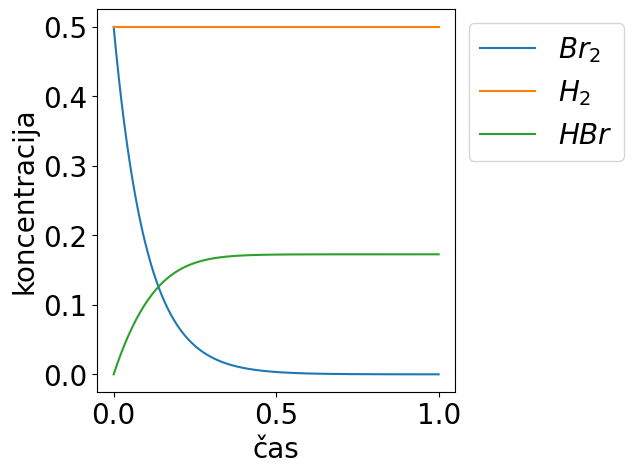

In [10]:
plt.plot(X, Br2, label='$Br_2$')
#plt.plot(X, Br, label='$Br$')
plt.plot(X, H2, label='$H_2$')
#plt.plot(X, H, label='$H$')
plt.plot(X, HBr, label='$HBr$')
plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
plt.xlabel('čas')
plt.ylabel('koncentracija')

In [11]:
brom = []
vodik = []
bromid = []
variacije = [0.001, 1, 100]
for i in variacije:
    k = 1 #param
    p = 1
    q = 1
    s = 1
    m = 2.5 #podatek
    r = k/2/m * (q/2/p)**(0.5)
    t = m*s
    x = np.linspace(0, 10, 1000)
    X = [i / x[-1] for i in x] #normiran čas

    HBr_0 = 0. #parameter
    razmerje = i #podatek 100, 1, 0.01
    H2_0 = razmerje*(1-HBr_0) / (razmerje+1)
    Br2_0 = (1-HBr_0) / (razmerje+1)
    začetno = [H2_0, Br2_0, HBr_0, 0, 0] #H2, Br2, HBr, H, Br

    rez = odeint(brom_stac, začetno, x, args=(p,q,r,s,t))
    H2, Br2, HBr, H, Br = rez.T
    brom.append(Br2)
    vodik.append(H2)
    bromid.append(HBr)

In [12]:
H2_data = []
Br2_data = []
HBr_data = []
n=2000
param = [i for i in range(n+1)]
param = list(np.linspace(0,10,2000))
for i in param:
    k = 1 #param
    p = 1
    q = 1
    s = 1
    m = i #podatek
    r = k/2/m * (q/2/p)**(0.5)
    t = m*s
    x = np.linspace(0, 10, 1000)
    X = [i / x[-1] for i in x] #normiran čas

    HBr_0 = 0 #parameter
    razmerje = 1 #podatek 100, 1, 0.01
    H2_0 = razmerje*(1-HBr_0) / (razmerje+1)
    Br2_0 = (1-HBr_0) / (razmerje+1)
    začetno = [H2_0, Br2_0, HBr_0, 0, 0] #H2, Br2, HBr, H, Br

    rez = odeint(brom_stac, začetno, x, args=(p,q,r,s,t))
    H2, Br2, HBr, H, Br = rez.T

    H2_data.append([H2])
    Br2_data.append([Br2])
    HBr_data.append([HBr])

C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\2558802635.py:13: RuntimeWarning: divide by zero encountered in double_scalars
  r = k/2/m * (q/2/p)**(0.5)
C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\1113975186.py:12: RuntimeWarning: invalid value encountered in double_scalars
  vHBr = 2*r*t/s * (2*p/q)**(0.5) * Br2**(0.5) * H2 / (t/s + HBr/Br2)
C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\1113975186.py:16: RuntimeWarning: invalid value encountered in double_scalars
  vH2 = s*H*HBr - r*Br*H2


C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\3227281274.py:13: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cbar = plt.colorbar(sm, orientation='vertical', label='$m$')


Text(0, 0.5, '$[HBr]$')

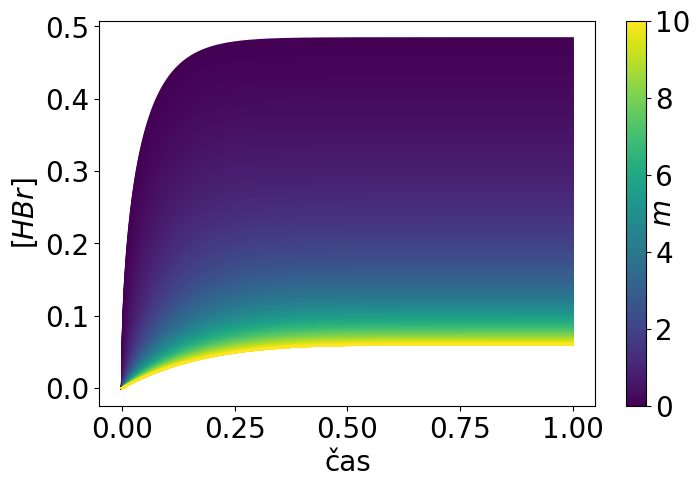

In [13]:
color = ['b','g','r']
cmap = plt.get_cmap('viridis')
plt.figure(figsize=(8,5))
for i in range(len(param)):
    #plt.plot(X, HBr_data[i][0], label=f'$R = {param[i]}$', color=color[i])
    #plt.plot(X, H2_data[i][0], label=f'$R = {param[i]}$', color=color[i])
    #plt.plot(X, Br2_data[i][0], label=f'$R = {param[i]}$', color=color[i])
    color_i = cmap(i / len(param))
    plt.plot(X, HBr_data[i][0], color=color_i)
#plt.legend(bbox_to_anchor=(1,1), ncol=1)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(param), vmax=max(param)))
#sm.set_array([])
cbar = plt.colorbar(sm, orientation='vertical', label='$m$')
cbar.ax.yaxis.set_label_coords(1.15, 0.5)
plt.xlabel('čas')
plt.ylabel('$[HBr]$')
#plt.tight_layout()
#plt.savefig('slike/potek_HBr_od_m.pdf')

3.naloga

In [14]:
def jodova_ura(y,x,r):
    A,B,C,D,E,F,G,H = y
    vA=-A*B
    vB=-2*A*B + 2*r*F*D
    vC=0
    vD=A*B - r*F*D
    vE=0
    vF=-2*r*F*D
    vG=0
    vH=0
    return [vA,vB,vC,vD,vE,vF,vG,vH]
def ura_nestac(y,x, p,q, r,s):
    A,B,C,D,E,F,G,H = y
    vA=-p*A*B
    vB=-p*A*B - q*C*B + r*F*D + s*G*F
    vC=p*A*B - -q*C*B
    vD=q*C*B - r*F*D
    vE=2*q*C*B
    vF=-r*F*D - s*G*F
    vG=r*F*D - s*G*F
    vH=s*G*F
    return [vA,vB,vC,vD,vE,vF,vG,vH]

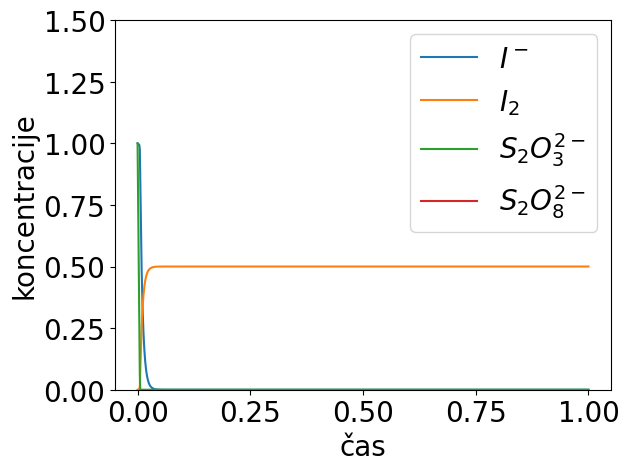

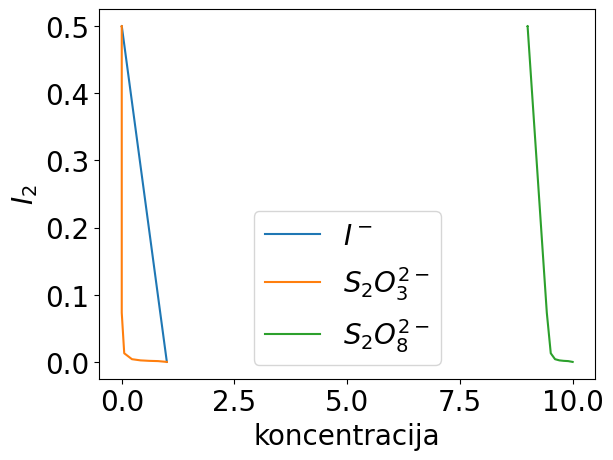

In [15]:
razm = 10000 #lambda = 1, 10, 100 = p/r
x = np.linspace(0, 10, 1000)
X = [i / x[-1] for i in x] #normiran čas

začetno = {'A':0, 'B':0, 'C':0, 'D':0, 'E':0, 'F':0, 'G':0, 'H':0}
začetno['A'] = 10 #S_2 O_8^2- persulfat v prebitku
začetno['B'] = 1 #I-
začetno['D'] = 0 #I2
začetno['F'] = 1 #S_2 O_3^2- tiosulfat

rez = odeint(jodova_ura, list(začetno.values()), x, args=(razm,))
A,B,C,D,E,F,G,H = rez.T
#A,B,C,D,E,F,G,H = zamenjava([A,B,C,D,E,F,G,H])

data = pd.DataFrame({
    '$S_2O_8^{2-}$':A, '$I^-$':B, '$IS_2O_8^{3-}$':C, '$I_2$':D, '$SO_4^{2-}$':E,
    '$S_2O_3^{2-}$':F, '$IS_2O_3^-$':G, '$S_4O_6^{2-}$':H
}, index=X)
#ax = data.plot.area()
#ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.show()
plt.plot(X, B, label='$I^-$')
plt.plot(X, D, label='$I_2$')
plt.plot(X, F, label='$S_2O_3^{2-}$')
plt.plot(X, A, label='$S_2O_8^{2-}$')
plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.ylim([0, 1.5])
plt.xlabel('čas')
plt.ylabel('koncentracije')
plt.show()
plt.plot(B, D, label='$I^-$')
plt.plot(F, D, label='$S_2O_3^{2-}$')
plt.plot(A, D, label='$S_2O_8^{2-}$')
plt.xlabel('koncentracija')
plt.ylabel('$I_2$')
plt.legend()
plt.show()

In [16]:
def identical(list1, list2, tolerance):
    list1 = list(list1)
    list2 = list(list2)
    for item1 in list1:
        for item2 in list2:
            if abs(item1 - item2) <= tolerance:
                location = list1.index(item1)
    return location
def middle_value(list1, tolerance):
    list1 = list(list1)
    for item1 in list1:
        if abs(item1 - (max(list1)-min(list1))/2) <= tolerance:
            location = list1.index(item1)
    return location

C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\3073362097.py:42: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  c1 = plt.colorbar(sm1, orientation='vertical', label='$I^-$')
C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\3073362097.py:45: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  c2 = plt.colorbar(sm2, orientation='vertical', label='$I_2$')
C:\Users\ravni\AppData\Local\Temp\ipykernel_3028\3073362097.py:48: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in 

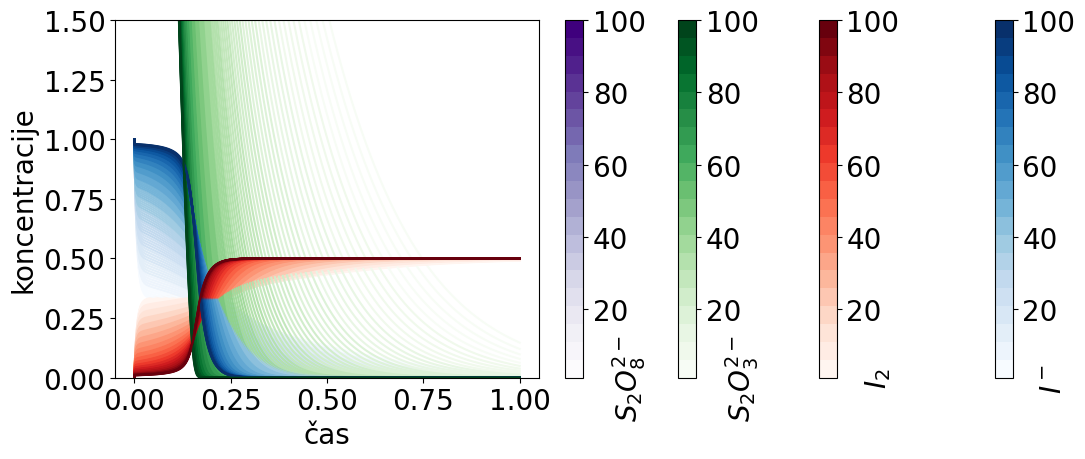

In [17]:
param = list(np.logspace(0,2,100)) #za razm
#param = list(np.logspace(0.00001,1,100)) #za konc F
A_data = []
B_data = []
D_data = []
F_data = []
t_reakc = []
for i in param:
    razm = i #lambda = 1, 10, 100 = r/p
    x = np.linspace(0, 5, 1000)
    X = [i / x[-1] for i in x] #normiran čas

    začetno = {'A':0, 'B':0, 'C':0, 'D':0, 'E':0, 'F':0, 'G':0, 'H':0}
    začetno['A'] = 10 #S_2 O_8^2- persulfat v prebitku
    začetno['B'] = 1 #I-
    začetno['D'] = 0 #I2
    začetno['F'] = 10 #S_2 O_3^2- tiosulfat

    rez = odeint(jodova_ura, list(začetno.values()), x, args=(razm,))
    A,B,C,D,E,F,G,H = rez.T
    
    t_reakc.append(X[middle_value(D, 0.1)])
    A_data.append(A)
    B_data.append(B)
    D_data.append(D)
    F_data.append(F)
cmin = 0
cmap1 = mpl.colors.ListedColormap(mpl.cm.Blues(np.linspace(0,1,20))[cmin:,:-1])
cmap2 = mpl.colors.ListedColormap(mpl.cm.Reds(np.linspace(0,1,20))[cmin:,:-1])
cmap3 = mpl.colors.ListedColormap(mpl.cm.Greens(np.linspace(0,1,20))[cmin:,:-1])
cmap4 = mpl.colors.ListedColormap(mpl.cm.Purples(np.linspace(0,1,20))[cmin:,:-1])
plt.figure(figsize=(12,5))
for i in range(len(param)):
    plt.plot(X, B_data[i], label=f'$I^-(\lambda = {param[i]})$', color=cmap1(i / len(param)))
    plt.plot(X, F_data[i], label=f'$S_2O_3^{{2-}}(\lambda = {param[i]})$', color=cmap3(i / len(param)))
    plt.plot(X, A_data[i], label=f'$S_2O_8^{{2-}}(\lambda = {param[i]})$', color=cmap4(i / len(param)))
    plt.plot(X, D_data[i], label=f'$I_2(\lambda = {param[i]})$', color=cmap2(i / len(param)))
plt.ylim([0, 1.5])
plt.xlabel('čas')
plt.ylabel('koncentracije')
sm1 = plt.cm.ScalarMappable(cmap=cmap1, norm=plt.Normalize(vmin=min(param), vmax=max(param)))
c1 = plt.colorbar(sm1, orientation='vertical', label='$I^-$')
c1.ax.yaxis.set_label_coords(2.5, 0)
sm2 = plt.cm.ScalarMappable(cmap=cmap2, norm=plt.Normalize(vmin=min(param), vmax=max(param)))
c2 = plt.colorbar(sm2, orientation='vertical', label='$I_2$')
c2.ax.yaxis.set_label_coords(2.5, 0)
sm3 = plt.cm.ScalarMappable(cmap=cmap3, norm=plt.Normalize(vmin=min(param), vmax=max(param)))
c3 = plt.colorbar(sm3, orientation='vertical', label='$S_2O_3^{2-}$')
c3.ax.yaxis.set_label_coords(2.5, 0)
sm4 = plt.cm.ScalarMappable(cmap=cmap4, norm=plt.Normalize(vmin=min(param), vmax=max(param)))
c4 = plt.colorbar(sm4, orientation='vertical', label='$S_2O_8^{2-}$')
c4.ax.yaxis.set_label_coords(2.5, 0)
plt.tight_layout()
#plt.savefig('slike/jod_konc_F.pdf')
plt.show()

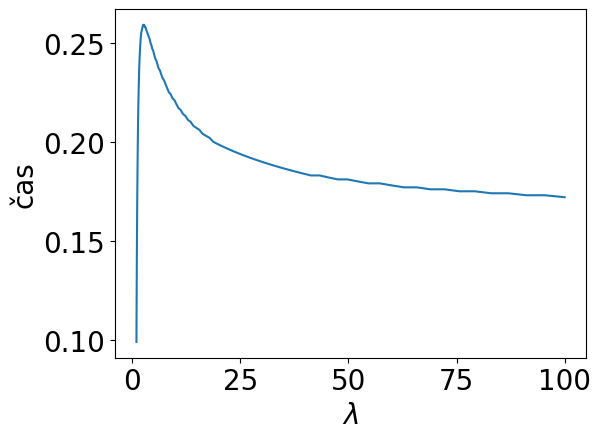

In [18]:
plt.plot(param, t_reakc)
plt.xlabel('$\lambda$')
plt.ylabel('čas')
plt.tight_layout()
#plt.savefig('slike/čas_reakc_lambda.pdf')

In [19]:
def jodova_ura_ivp(t,y,r):
    A,B,C,D,E,F,G,H = y
    vA=-A*B
    vB=-2*A*B + 2*r*F*D
    vC=0
    vD=A*B - r*F*D
    vE=0
    vF=-2*r*F*D
    vG=0
    vH=0
    return [vA,vB,vC,vD,vE,vF,vG,vH]
def ura_nestac_ivp(t,y, p,q, r,s):
    A,B,C,D,E,F,G,H = y
    vA=-p*A*B
    vB=-p*A*B - q*C*B + r*F*D + s*G*F
    vC=p*A*B - -q*C*B
    vD=q*C*B - r*F*D
    vE=2*q*C*B
    vF=-r*F*D - s*G*F
    vG=r*F*D - s*G*F
    vH=s*G*F
    return [vA,vB,vC,vD,vE,vF,vG,vH]

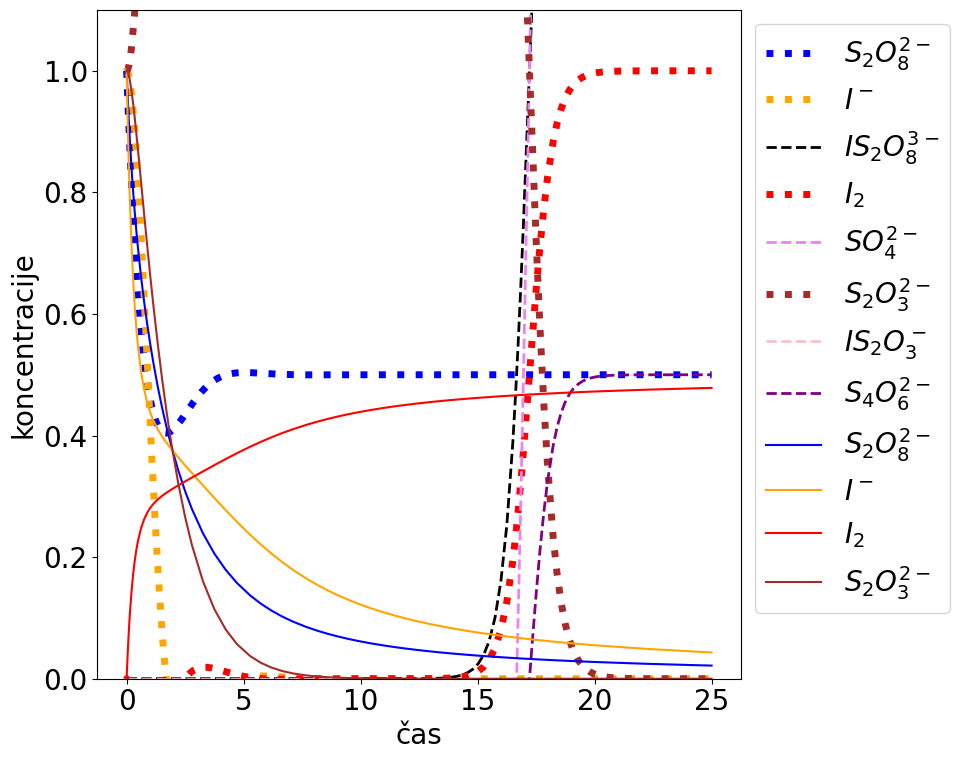

In [20]:
razm = 1 #lambda = 1, 10, 100 = p/r
x = np.linspace(0, 25, 5000)
X = [i / x[-1] for i in x] #normiran čas

začetno = {'A':0, 'B':0, 'C':0, 'D':0, 'E':0, 'F':0, 'G':0, 'H':0}
začetno['A'] = 1 #S_2 O_8^2- persulfat v prebitku
začetno['B'] = 1 #I-
začetno['D'] = 0 #I2
začetno['F'] = 1 #S_2 O_3^2- tiosulfat

rez = solve_ivp(jodova_ura_ivp, (x[0],x[-1]), list(začetno.values()), method='LSODA', args=(razm,))
A,B,C,D,E,F,G,H = rez.y
X = rez.t
#A,B,C,D,E,F,G,H = zamenjava([A,B,C,D,E,F,G,H])

p = 1
r = p*razm #r>p
ll = 4.92
r1 = ll*1000000. #param
r2 = ll*1000000. #param
q = r1*p #q>p
s = r2*r #s>r
rez1 = solve_ivp(ura_nestac_ivp, (x[0],x[-1]), list(začetno.values()), method='BDF', args=(p,q,r,s))
A1,B1,C1,D1,E1,F1,G1,H1 = rez1.y
X1 = rez1.t

plt.figure(figsize=(10,8))
plt.plot(X1, A1, ':', color='blue', label='$S_2O_8^{2-}$',linewidth=5.0)
plt.plot(X1, B1, ':', color='orange', label='$I^-$',linewidth=5.0)
plt.plot(X1, C1, '--', color='black', label='$IS_2O_8^{3-}$',linewidth=2.0)
plt.plot(X1, D1, ':', color='red', label='$I_2$',linewidth=5.0)
plt.plot(X1, E1, '--', color='violet', label='$SO_4^{2-}$',linewidth=2.0)
plt.plot(X1, F1, ':', color='brown', label='$S_2O_3^{2-}$',linewidth=5.0)
plt.plot(X1, G1, '--', color='pink', label='$IS_2O_3^-$',linewidth=2.0)
plt.plot(X1, H1, '--', color='purple', label='$S_4O_6^{2-}$',linewidth=2.0)

plt.plot(X, A, color='blue', label='$S_2O_8^{2-}$')
plt.plot(X, B, color='orange', label='$I^-$')
plt.plot(X, D, color='red', label='$I_2$')
plt.plot(X, F, color='brown', label='$S_2O_3^{2-}$')

plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.ylim([0, 1.1])
plt.xlabel('čas')
plt.ylabel('koncentracije')
plt.tight_layout()
#plt.savefig('slike/stac_nestac_pribl.pdf')
plt.show()

belousov-zhabotinsky

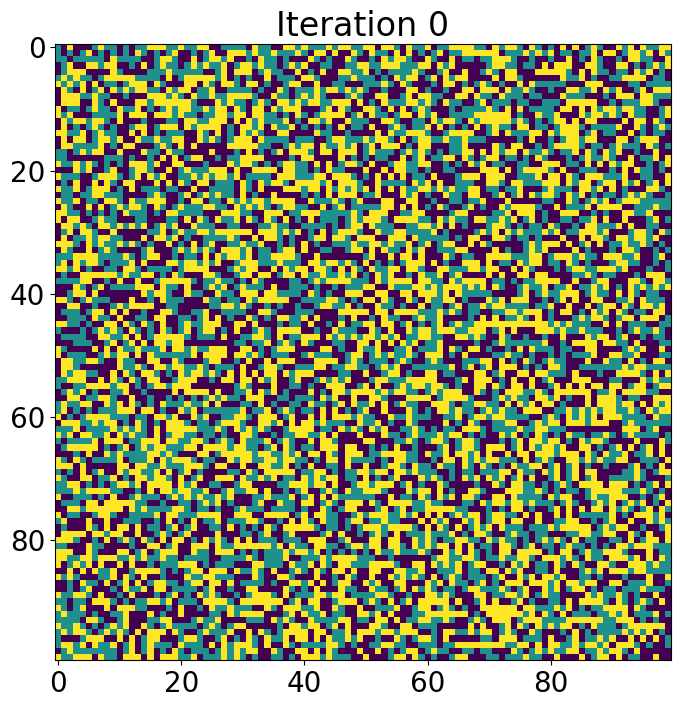

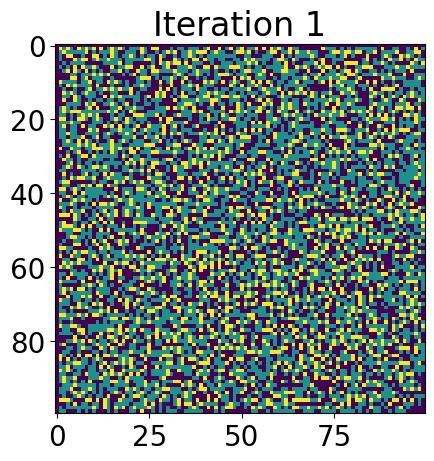

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
k1 = 2
k2 = 3
g = 0.1

# Grid dimensions
width, height = 100, 100

# Initialize the grid with random values between 0 and 2
grid = np.random.randint(0, 3, (width, height), dtype=int)

# Define the Moore neighborhood
neighborhood = np.array([[1, 1, 1],
                        [1, 0, 1],
                        [1, 1, 1]])

def update_grid(grid):
    new_grid = grid.copy()
    for x in range(width):
        for y in range(height):
            cell = grid[x, y]
            neighbors = grid[x - 1:x + 2, y - 1:y + 2]
            a = np.sum(neighbors == 1)  # Count infected cells
            b = np.sum(neighbors == 2)  # Count ill cells

            if cell == 0:
                new_grid[x, y] = int(a / k1) + int(b / k2)
            elif cell == 2:
                new_grid[x, y] = 0
            else:
                s = np.sum(neighbors)
                new_grid[x, y] = int(s / (a + b + 1)) + g

    return new_grid

# Number of iterations
num_iterations = 2

# Visualization
plt.figure(figsize=(8, 8))
for i in range(num_iterations):
    plt.clf()
    plt.imshow(grid, cmap='viridis', vmin=0, vmax=2)
    plt.title(f"Iteration {i}")
    plt.pause(0.1)
    plt.show()
    grid = update_grid(grid)

plt.show()

In [22]:
def B_Z(t,y,alpha,beta,gamma):
    A,B,C = y
    vA = alpha*A*B - gamma*A*C
    vB = beta*B*C - alpha*A*B
    vC = gamma*A*C - beta*B*C
    return [vA,vB,vC]

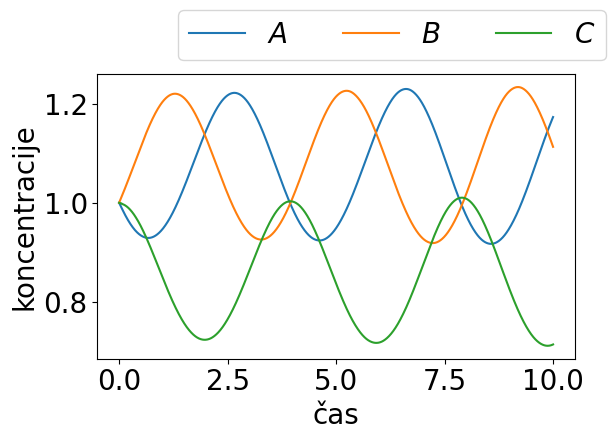

In [44]:
alpha = 0.8
beta = 1
gamma = 1
x = np.linspace(0, 10, 5000)
X = [i / x[-1] for i in x] #normiran čas
začetno = {'A':1, 'B':1, 'C':1}

rez = solve_ivp(B_Z, (x[0],x[-1]), list(začetno.values()), method='LSODA', args=(alpha,beta,gamma), t_eval=x)
A,B,C = rez.y
X = rez.t

plt.plot(X, A, label='$A$')
plt.plot(X, B, label='$B$')
plt.plot(X, C, label='$C$')
plt.legend(bbox_to_anchor=(0.14, 1), ncol=3)
#plt.ylim([0, 1.5])
plt.xlabel('čas')
plt.ylabel('koncentracije')
plt.tight_layout()
#plt.savefig('slike/B_Z_konc.pdf')
plt.show()